In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
CSV_FILE = (
    r"C:\Users\arshi\OneDrive\Desktop\CLC-05\Group A Deadline-28 Nov 26 Model_CLC_05 - Copy of Master.csv"
)

df = pd.read_csv(CSV_FILE, encoding="utf-8-sig")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (577, 9)
Columns: ['S No', 'Country', 'City', 'Company', 'Contact', 'Google Maps', 'Category', 'Rating', 'Review']


,S No,Country,City,Company,Contact,Google Maps,Category,Rating,Review
0,1,India,Chennai,Boss Gym,9840233287,https://maps.app.goo.gl/yAaputauAErTq4ss5,Gym,4.5,52
1,2,India,Chennai,TONE N TUNE GYM,9962977031,https://maps.app.goo.gl/btbw8azCsPWU47nC9,Gym,4.8,51
2,3,India,Chennai,VR Fitness Studio,8056255689,https://maps.app.goo.gl/tiyySvSi1YQFPkEt7,Gym,5.0,14
3,4,India,Chennai,Glow fitness,7094131131,https://maps.app.goo.gl/XUUE8XamHPVxuSSy8,Gym,5.0,21
4,5,India,Chennai,AUGUSTINS GYM,9940575355,https://maps.app.goo.gl/1v65XZUdegDNCyBV9,Gym,4.4,246


In [4]:
required_columns = ["Company", "Country", "Rating", "Review"]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")
df["Review"] = pd.to_numeric(
    df["Review"].astype("string").str.replace(",", "", regex=False),
    errors="coerce"
)

if df["Rating"].dropna().lt(0).any() or df["Rating"].dropna().gt(5).any():
    raise ValueError("Ratings must be between 0 and 5.")
if df["Review"].dropna().lt(0).any():
    raise ValueError("Review counts cannot be negative.")

print("Total businesses:", len(df))
print("Missing ratings:", df["Rating"].isna().sum())
print("Missing review counts:", df["Review"].isna().sum())

Total businesses: 577
Missing ratings: 0
Missing review counts: 0


In [5]:
country_clean = df["Country"].astype("string").str.strip().str.casefold()

df["Business_Classification"] = np.select(
    [
        country_clean.eq("india"),
        country_clean.notna() & country_clean.ne("")
    ],
    ["Indian", "Foreign"],
    default="Unknown"
)

print(df["Business_Classification"].value_counts(dropna=False))

Business_Classification
Indian     562
Foreign     15
Name: count, dtype: int64


In [6]:
# Businesses with both rating and review count equal to zero, or missing values,
# are kept in the final dataset but excluded from review scoring/model training.
valid_review_mask = (
    df["Rating"].notna()
    & df["Review"].notna()
    & ~((df["Rating"] == 0) & (df["Review"] == 0))
)

model_df = df.loc[valid_review_mask].copy()

print("Businesses with usable review data:", len(model_df))
print("Businesses without usable review data:", len(df) - len(model_df))

Businesses with usable review data: 568
Businesses without usable review data: 9


In [7]:
model_df["Log_Review_Count"] = np.log1p(model_df["Review"])

min_reviews = model_df["Log_Review_Count"].min()
max_reviews = model_df["Log_Review_Count"].max()

if max_reviews > min_reviews:
    model_df["Normalized_Review_Count"] = (
        (model_df["Log_Review_Count"] - min_reviews)
        / (max_reviews - min_reviews)
    )
else:
    model_df["Normalized_Review_Count"] = 0.0

model_df["Normalized_Rating"] = model_df["Rating"] / 5

model_df["Review_Performance_Score"] = (
    0.60 * model_df["Normalized_Review_Count"]
    + 0.40 * model_df["Normalized_Rating"]
)

display(model_df[
    ["Company", "Country", "Rating", "Review",
     "Normalized_Review_Count", "Normalized_Rating",
     "Review_Performance_Score"]
].head(10))

,Company,Country,Rating,Review,Normalized_Review_Count,Normalized_Rating,Review_Performance_Score
0,Boss Gym,India,4.5,52,0.550721,0.90,0.690433
1,TONE N TUNE GYM,India,4.8,51,0.54752,0.96,0.712512
2,VR Fitness Studio,India,5.0,14,0.338603,1.00,0.603162
3,Glow fitness,India,5.0,21,0.402964,1.00,0.641778
4,AUGUSTINS GYM,India,4.4,246,0.809365,0.88,0.837619
5,Throwback Fitness Studio otteri,India,4.4,43,0.519447,0.88,0.663668
6,Body Stylle Fitness Centre,India,4.8,628,0.966448,0.96,0.963869
7,Fitness Avenue gym,India,5.0,336,0.861577,1.00,0.916946
8,EPIC GYM,India,4.4,90,0.641563,0.88,0.736938
9,VARS HI-TECH GYM,India,4.8,16,0.359636,0.96,0.599782


In [8]:
q1 = model_df["Review_Performance_Score"].quantile(0.25)
q3 = model_df["Review_Performance_Score"].quantile(0.75)

model_df["Priority"] = np.select(
    [
        model_df["Review_Performance_Score"] <= q1,
        model_df["Review_Performance_Score"] <= q3
    ],
    ["Low", "Medium"],
    default="High"
)

print("Review priority counts:")
print(model_df["Priority"].value_counts())
print("\nScore thresholds:")
print("Low / Medium boundary (25th percentile):", round(q1, 4))
print("Medium / High boundary (75th percentile):", round(q3, 4))

Review priority counts:
Priority
Medium    285
Low       142
High      141
Name: count, dtype: int64

Score thresholds:
Low / Medium boundary (25th percentile): 0.61
Medium / High boundary (75th percentile): 0.7769


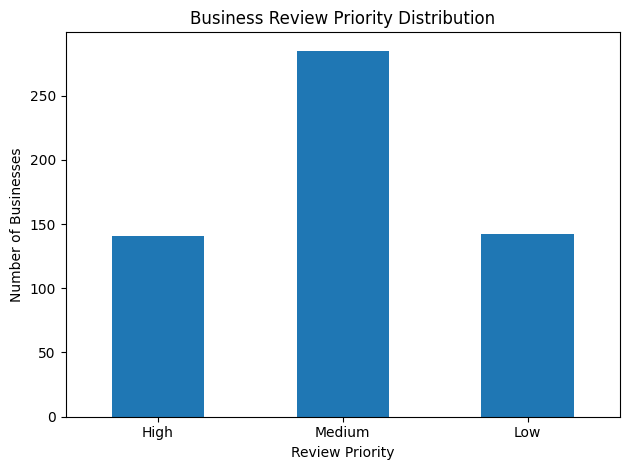

In [9]:
priority_counts = (
    model_df["Priority"]
    .value_counts()
    .reindex(["High", "Medium", "Low"], fill_value=0)
)

priority_counts.plot(kind="bar", rot=0)
plt.title("Business Review Priority Distribution")
plt.xlabel("Review Priority")
plt.ylabel("Number of Businesses")
plt.tight_layout()
plt.show()

In [10]:
features = ["Normalized_Review_Count", "Normalized_Rating"]
X = model_df[features]
y = model_df["Priority"]

class_counts = y.value_counts()
if len(class_counts) < 2 or class_counts.min() < 2:
    raise ValueError(
        "There are not enough records in each priority class for a stratified "
        "train/test split. Check the dataset and priority distribution."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

review_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(max_iter=2000))
])

review_model.fit(X_train, y_train)
y_pred = review_model.predict(X_test)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Training records: 454
Testing records: 114
Accuracy: 0.9825

Classification Report:
              precision    recall  f1-score   support

        High       1.00      0.96      0.98        28
         Low       1.00      0.97      0.98        29
      Medium       0.97      1.00      0.98        57

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



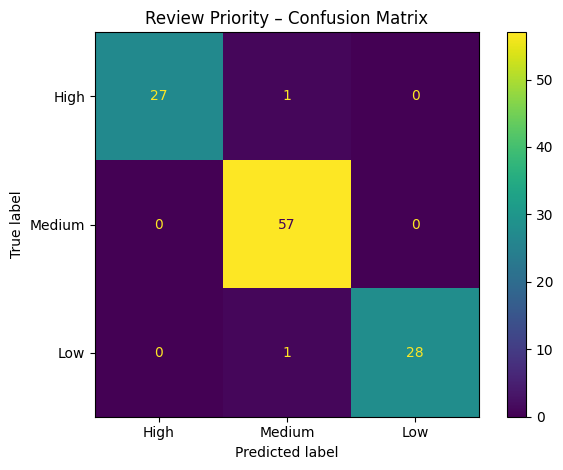

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=["High", "Medium", "Low"])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["High", "Medium", "Low"]
)
disp.plot()
plt.title("Review Priority – Confusion Matrix")
plt.tight_layout()
plt.show()

In [12]:
model_df["Predicted_Priority"] = review_model.predict(X)
model_df["Predicted_Probability"] = review_model.predict_proba(X).max(axis=1)

display(model_df[
    ["Company", "Country", "Rating", "Review",
     "Review_Performance_Score", "Priority",
     "Predicted_Priority", "Predicted_Probability"]
].head(10))

,Company,Country,Rating,Review,Review_Performance_Score,Priority,Predicted_Priority,Predicted_Probability
0,Boss Gym,India,4.5,52,0.690433,Medium,Medium,0.969329
1,TONE N TUNE GYM,India,4.8,51,0.712512,Medium,Medium,0.961813
2,VR Fitness Studio,India,5.0,14,0.603162,Low,Low,0.556835
3,Glow fitness,India,5.0,21,0.641778,Medium,Medium,0.816744
4,AUGUSTINS GYM,India,4.4,246,0.837619,High,High,0.949241
5,Throwback Fitness Studio otteri,India,4.4,43,0.663668,Medium,Medium,0.934042
6,Body Stylle Fitness Centre,India,4.8,628,0.963869,High,High,0.999909
7,Fitness Avenue gym,India,5.0,336,0.916946,High,High,0.998993
8,EPIC GYM,India,4.4,90,0.736938,Medium,Medium,0.897499
9,VARS HI-TECH GYM,India,4.8,16,0.599782,Low,Low,0.576553


In [13]:
# Preserve every original business row, including those without review data.
final_output = df.copy()

new_columns = [
    "Log_Review_Count",
    "Normalized_Review_Count",
    "Normalized_Rating",
    "Review_Performance_Score",
    "Priority",
    "Predicted_Priority",
    "Predicted_Probability"
]

for col in new_columns:
    final_output[col] = np.nan

final_output["Priority"] = "No Review Data"
final_output["Predicted_Priority"] = "No Review Data"

for col in new_columns:
    if col in model_df.columns:
        final_output.loc[model_df.index, col] = model_df[col]

print("Final output rows:", len(final_output))
print("\nPriority counts including businesses without review data:")
print(final_output["Priority"].value_counts(dropna=False))
display(final_output.head())

Final output rows: 577

Priority counts including businesses without review data:
Priority
Medium            285
Low               142
High              141
No Review Data      9
Name: count, dtype: int64


,S No,Country,City,Company,Contact,Google Maps,Category,Rating,Review,Business_Classification,Log_Review_Count,Normalized_Review_Count,Normalized_Rating,Review_Performance_Score,Priority,Predicted_Priority,Predicted_Probability
0,1,India,Chennai,Boss Gym,9840233287,https://maps.app.goo.gl/yAaputauAErTq4ss5,Gym,4.5,52,Indian,3.970292,0.550721,0.90,0.690433,Medium,Medium,0.969329
1,2,India,Chennai,TONE N TUNE GYM,9962977031,https://maps.app.goo.gl/btbw8azCsPWU47nC9,Gym,4.8,51,Indian,3.951244,0.547520,0.96,0.712512,Medium,Medium,0.961813
2,3,India,Chennai,VR Fitness Studio,8056255689,https://maps.app.goo.gl/tiyySvSi1YQFPkEt7,Gym,5.0,14,Indian,2.708050,0.338603,1.00,0.603162,Low,Low,0.556835
3,4,India,Chennai,Glow fitness,7094131131,https://maps.app.goo.gl/XUUE8XamHPVxuSSy8,Gym,5.0,21,Indian,3.091042,0.402964,1.00,0.641778,Medium,Medium,0.816744
4,5,India,Chennai,AUGUSTINS GYM,9940575355,https://maps.app.goo.gl/1v65XZUdegDNCyBV9,Gym,4.4,246,Indian,5.509388,0.809365,0.88,0.837619,High,High,0.949241


In [14]:
# Complete review analysis output
final_output.to_csv("CLC_02_Final_Review_Analysis.csv", index=False)

# Separate priority files
for priority in ["High", "Medium", "Low", "No Review Data"]:
    priority_df = final_output[final_output["Priority"] == priority].copy()
    filename = f"CLC_02_{priority.replace(' ', '_')}_Priority.csv"
    priority_df.to_csv(filename, index=False)
    print(f"{filename}: {len(priority_df)} businesses")

# Separate Indian and Foreign business files
indian_df = final_output[final_output["Business_Classification"] == "Indian"].copy()
foreign_df = final_output[final_output["Business_Classification"] == "Foreign"].copy()

indian_df.to_csv("CLC_02_Indian_Businesses.csv", index=False)
foreign_df.to_csv("CLC_02_Foreign_Businesses.csv", index=False)

print("CLC_02_Indian_Businesses.csv:", len(indian_df), "businesses")
print("CLC_02_Foreign_Businesses.csv:", len(foreign_df), "businesses")

CLC_02_High_Priority.csv: 141 businesses
CLC_02_Medium_Priority.csv: 285 businesses
CLC_02_Low_Priority.csv: 142 businesses
CLC_02_No_Review_Data_Priority.csv: 9 businesses
CLC_02_Indian_Businesses.csv: 562 businesses
CLC_02_Foreign_Businesses.csv: 15 businesses


In [15]:
for filename in [
    "CLC_02_Final_Review_Analysis.csv",
    "CLC_02_High_Priority.csv",
    "CLC_02_Medium_Priority.csv",
    "CLC_02_Low_Priority.csv",
    "CLC_02_No_Review_Data_Priority.csv",
    "CLC_02_Indian_Businesses.csv",
    "CLC_02_Foreign_Businesses.csv"
]:
    check_df = pd.read_csv(filename)
    print(f"{filename}: {len(check_df)} rows")

print("\nAll review analysis CSV exports verified.")

CLC_02_Final_Review_Analysis.csv: 577 rows
CLC_02_High_Priority.csv: 141 rows
CLC_02_Medium_Priority.csv: 285 rows
CLC_02_Low_Priority.csv: 142 rows
CLC_02_No_Review_Data_Priority.csv: 9 rows
CLC_02_Indian_Businesses.csv: 562 rows
CLC_02_Foreign_Businesses.csv: 15 rows

All review analysis CSV exports verified.


In [17]:
# ONE SHARED PRIORITY PER CLEANED CATEGORY

category_scores = (
    model_df.groupby("Category")
    .agg(
        Average_Review_Score=("Review_Performance_Score", "mean"),
        Business_Count=("Company", "count")
    )
    .reset_index()
)

# Rank cleaned categories by average review score
category_scores["Category_Rank"] = (
    category_scores["Average_Review_Score"]
    .rank(method="first", ascending=False)
)

# Assign one priority to each cleaned category
n_categories = len(category_scores)

category_scores["Category_Priority"] = np.select(
    [
        category_scores["Category_Rank"] <= n_categories / 3,
        category_scores["Category_Rank"] <= 2 * n_categories / 3
    ],
    ["High", "Medium"],
    default="Low"
)

# Map the same priority to every business in that category
priority_map = category_scores.set_index(
    "Category"
)["Category_Priority"]

model_df["Category_Priority"] = (
    model_df["Category"].map(priority_map)
)

# Verify uniqueness
assert category_scores["Category"].is_unique

print("Category classification completed.")
display(
    category_scores.sort_values(
        "Average_Review_Score",
        ascending=False
    )
)

Category classification completed.


,Category,Average_Review_Score,Business_Count,Category_Rank,Category_Priority
1,Gym,0.692928,394,1.0,Medium
0,Fitness Center,0.670608,174,2.0,Low


In [19]:
category_scores.to_csv(
    "CLC_02_Cleaned_Category_Priority_Mapping.csv",
    index=False
)

for priority in ["High", "Medium", "Low"]:
    categories = sorted(
        category_scores.loc[
            category_scores["Category_Priority"] == priority,
            "Category"
        ].dropna().unique()
    )

    print(f"\n{priority} Priority Categories:")
    print(", ".join(categories))


High Priority Categories:


Medium Priority Categories:
Gym

Low Priority Categories:
Fitness Center


In [22]:
# Calculate category priority thresholds

category_scores = category_scores.copy()

category_scores["Average_Review_Score"] = pd.to_numeric(
    category_scores["Average_Review_Score"],
    errors="coerce"
)

category_scores = category_scores.dropna(
    subset=["Average_Review_Score"]
)

n = len(category_scores)

print("CATEGORY PRIORITY THRESHOLDS")
print("--------------------------------")

if n == 0:
    print("No category review scores available.")

else:
    # Calculate percentile-based thresholds
    low_threshold = category_scores["Average_Review_Score"].quantile(0.33)
    high_threshold = category_scores["Average_Review_Score"].quantile(0.67)

    print(f"High Priority: Average Review Score >= {high_threshold:.4f}")

    print(
        f"Medium Priority: Average Review Score >= {low_threshold:.4f} "
        f"and < {high_threshold:.4f}"
    )

    print(f"Low Priority: Average Review Score < {low_threshold:.4f}")

    print("\nNumber of Categories:", n)

# No Review Data condition
print("\nNo Review Data: Both Rating and Review count are 0")

CATEGORY PRIORITY THRESHOLDS
--------------------------------
High Priority: Average Review Score >= 0.6856
Medium Priority: Average Review Score >= 0.6780 and < 0.6856
Low Priority: Average Review Score < 0.6780

Number of Categories: 2

No Review Data: Both Rating and Review count are 0


In [27]:
# Validate Cleaned Categories for CLC-05

# Get all unique cleaned categories
all_categories = set(
    df["Category"]
    .dropna()
    .astype(str)
    .str.strip()
    .unique()
)

# Categories assigned to the current project
expected_categories = {
    "Fitness Center",
    "Gym"
}

# Find missing and extra categories
missing_categories = expected_categories - all_categories
extra_categories = all_categories - expected_categories

print("CATEGORY VALIDATION REPORT")
print("--------------------------------")

print("Total Cleaned Categories:", len(all_categories))
print("Total Expected Categories:", len(expected_categories))

print("\nCategories Found:")
print(sorted(all_categories))

print("\nMissing Categories:")
print(sorted(missing_categories) if missing_categories else "None")

print("\nExtra Categories:")
print(sorted(extra_categories) if extra_categories else "None")

print("\nAll categories covered:", all_categories == expected_categories)

CATEGORY VALIDATION REPORT
--------------------------------
Total Cleaned Categories: 2
Total Expected Categories: 2

Categories Found:
['Fitness Center', 'Gym']

Missing Categories:
None

Extra Categories:
None

All categories covered: True


In [28]:
# Calculate category-wise priority

category_scores = category_scores.sort_values(
    "Average_Review_Score",
    ascending=False
).reset_index(drop=True)

n = len(category_scores)

if n == 0:
    print("No category data available.")

else:
    # Calculate median score as the priority threshold
    priority_threshold = category_scores["Average_Review_Score"].median()

    category_scores["Category_Priority"] = category_scores[
        "Average_Review_Score"
    ].apply(
        lambda x: "High" if x >= priority_threshold else "Low"
    )

    # With only two categories, Medium is not assigned
    print("CATEGORY PRIORITY THRESHOLD")
    print("--------------------------------")
    print(f"Priority Threshold: {priority_threshold:.4f}")
    print("High Priority: Score >= threshold")
    print("Low Priority: Score < threshold")
    print("Medium Priority: Not applicable with only two categories")

    display(category_scores)

CATEGORY PRIORITY THRESHOLD
--------------------------------
Priority Threshold: 0.6818
High Priority: Score >= threshold
Low Priority: Score < threshold
Medium Priority: Not applicable with only two categories


,Category,Average_Review_Score,Business_Count,Category_Rank,Category_Priority
0,Gym,0.692928,394,1.0,High
1,Fitness Center,0.670608,174,2.0,Low
